In [1]:
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt

## #7

In [4]:
# Data
x = tf.constant([0.03, 0.19, 0.34, 0.46, 0.78, 0.81, 1.08, 1.18, 1.39, 1.60, 1.65, 1.90])
y = tf.constant([0.67, 0.85, 1.05, 1.0, 1.40, 1.5, 1.3, 1.54, 1.55, 1.68, 1.73, 1.6 ])

# Model
model = tf.keras.Sequential(
    [
        tf.keras.layers.Dense(1, input_shape=(1,))
    ]
)

# Compile
model.compile(loss=tf.keras.losses.mse, optimizer=tf.keras.optimizers.SGD())

# Train
model.fit(x, y, epochs=1000)

Epoch 1/1000


c:\Users\ahmad\anaconda3\envs\tf-env\lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 452ms/step - loss: 0.2410
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.2333
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.2262
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.2197
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.2135
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.2079
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.2026
Epoch 8/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.1976
Epoch 9/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1930
Epoch 10/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.1887
Epoch 11/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.1847
Epoch 12/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.1810
Epoch 13/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.1775
Epoch 14/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.1742
Epoch 15/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.1711
Epoch 16/1000
1/

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


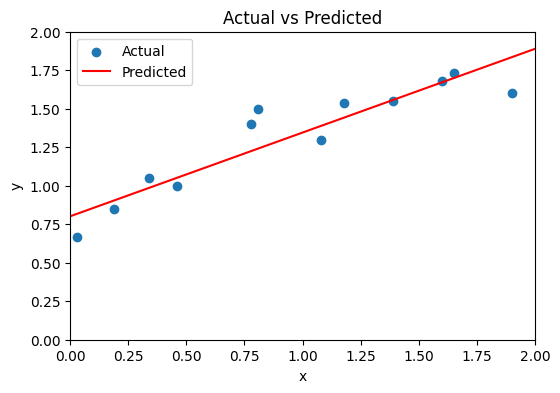

In [7]:
# Predict
x_values = np.linspace(0, 2, 100)
y_pred = model.predict(x_values)

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(x, y, label='Actual')
plt.plot(x_values, y_pred, color='red', label='Predicted')
plt.xlim([0, 2])
plt.ylim([0, 2])
plt.xlabel('x')
plt.ylabel('y')
plt.title('Actual vs Predicted')
plt.legend()
plt.show()

In [8]:
weights, bias = model.layers[0].get_weights()
phi0 = bias
phi1 = weights[0]
print(phi0, phi1)

[0.80117005] [0.54395014]


## #8 ReLU

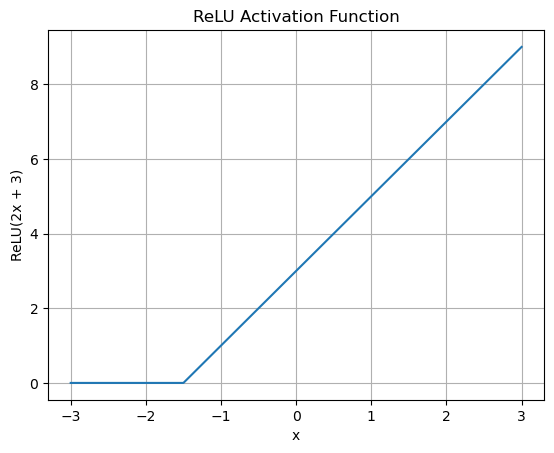

In [2]:
def relu(z):
    return tf.maximum(0, z)

def plot_relu(x, z, ylabel):
    plt.plot(x, relu(z))
    plt.title('ReLU Activation Function')
    plt.xlabel('x')
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.show()

x = tf.linspace(-3, 3, 1000)
z = 2 * x + 3
plot_relu(x, z, ylabel='ReLU(2x + 3)')

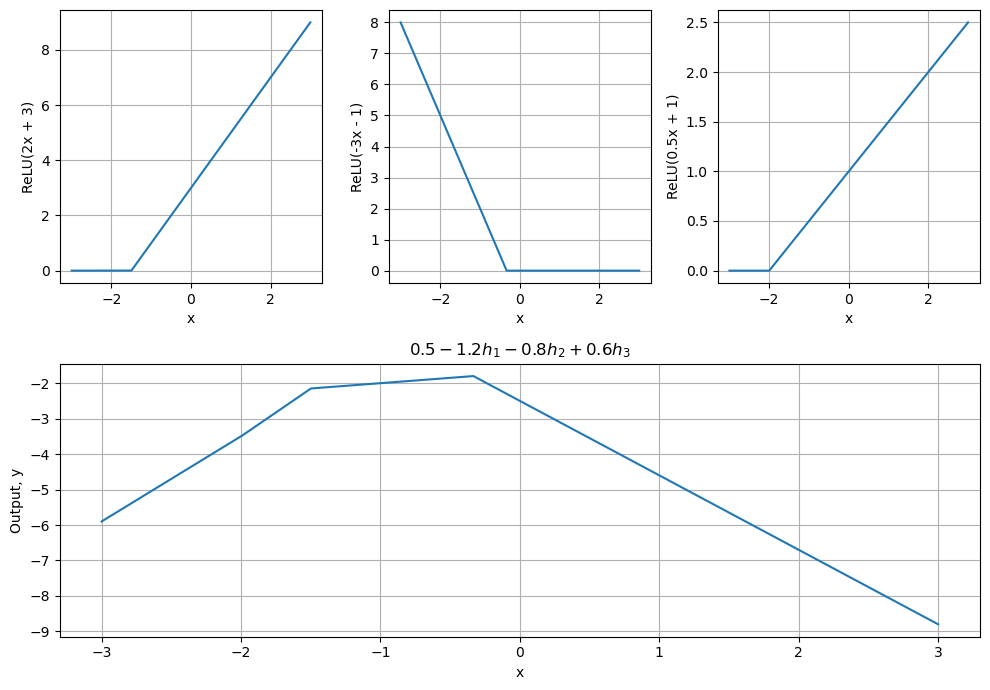

In [3]:
def relu(z):
    return tf.maximum(0, z)

def plot_relu(x, z, ylabel, subplot_position):
    plt.subplot(2, 3, subplot_position)
    plt.plot(x, relu(z))
    plt.xlabel('x')
    plt.ylabel(ylabel)
    plt.grid(True)

x = tf.linspace(-3, 3, 1000)

# Define three hidden layers
z1 = 2 * x + 3
z2 = -3 * x - 1
z3 = 0.5 * x + 1

# Define weights for each hidden layer
phi0 = 0.5
phi1 = -1.2
phi2 = -0.8
phi3 = 0.6

# Sum the outputs of the three hidden layers with their respective weights
z_sum = phi0 + phi1 * relu(z1) + phi2 * relu(z2) + phi3 * relu(z3)

plt.figure(figsize=(10, 7))

# Plot each hidden layer
plot_relu(x, z1, r'ReLU(2x + 3)', 1)
plot_relu(x, z2, r'ReLU(-3x - 1)', 2)
plot_relu(x, z3, r'ReLU(0.5x + 1)', 3)

# Plot the sum of the three hidden layers
plt.subplot(2, 1, 2)
plt.plot(x, z_sum)
plt.title(r'$0.5 - 1.2 h_1 - 0.8 h_2 + 0.6 h_3$')
plt.xlabel('x')
plt.ylabel('Output, y')
plt.grid(True)

plt.tight_layout()
plt.show()

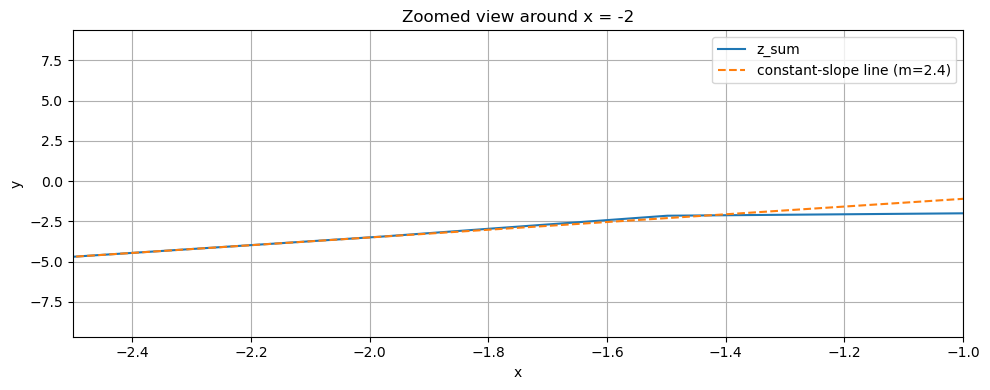

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(x, z_sum, label="z_sum")

m = 2.4  # choose a constant slope to compare (e.g., the left-slope region)
x0 = -2.0
y0 = -3.5
plt.plot(x, m*(x - x0) + y0, "--", label=f"constant-slope line (m={m})")

plt.xlim(-2.5, -1)
# plt.ylim(-4, -3)

plt.title("Zoomed view around x = -2")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## #9 Shallow Neural Networks

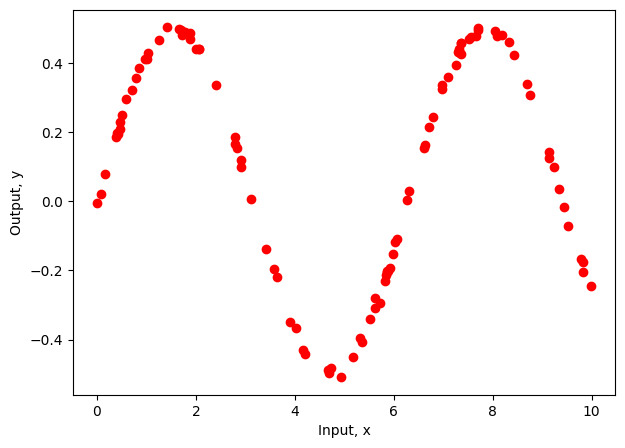

In [2]:
# Set the seed for reproducibility
tf.random.set_seed(0)

# Generate 100 random numbers between 0 and 10
x = 10 * tf.random.uniform(shape=(100,))

# Calculate y based on the formula with some noise added
y = 0.5 * tf.math.sin(x) + 0.01 * tf.random.normal(shape=(100,))

plt.figure(figsize=(7, 5))

# Create a scatter plot of the generated points with red color
plt.scatter(x, y, color='red')
plt.xlabel('Input, x')
plt.ylabel('Output, y')
plt.show()

In [17]:
# model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(50000, activation='relu', input_shape=(1, )),
    tf.keras.layers.Dense(1),
])

# compile
model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

# fit
model.fit(x, y, epochs=1000)

Epoch 1/1000
4/4 [==============================] - 0s 8ms/step - loss: 0.9622
Epoch 2/1000
4/4 [==============================] - 0s 10ms/step - loss: 0.3622
Epoch 3/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.2744
Epoch 4/1000
4/4 [==============================] - 0s 37ms/step - loss: 0.1457
Epoch 5/1000
4/4 [==============================] - 0s 19ms/step - loss: 0.1369
Epoch 6/1000
4/4 [==============================] - 0s 15ms/step - loss: 0.1718
Epoch 7/1000
4/4 [==============================] - 0s 13ms/step - loss: 0.1058
Epoch 8/1000
4/4 [==============================] - 0s 13ms/step - loss: 0.1606
Epoch 9/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.1197
Epoch 10/1000
4/4 [==============================] - 0s 11ms/step - loss: 0.1085
Epoch 11/1000
4/4 [==============================] - 0s 11ms/step - loss: 0.1374
Epoch 12/1000
4/4 [==============================] - 0s 10ms/step - loss: 0.1108
Epoch 13/1000
4/4 [===================

4/4 [==============================] - 0s 4ms/step


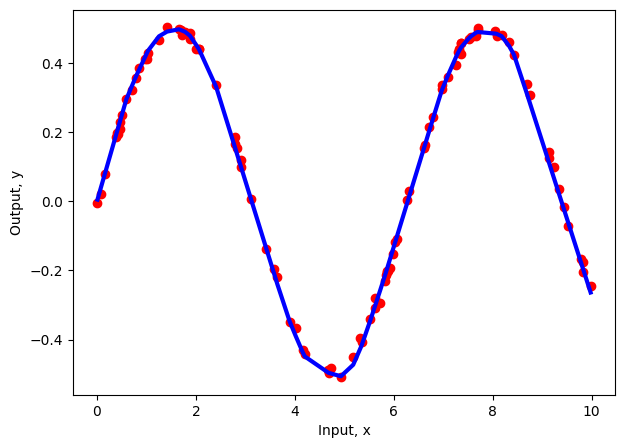

In [19]:
def plot_predictions(model, x, y):
    # Predict y values
    y_pred = model.predict(x)

    # Sort x and y_pred for line plot
    sorted_zip = sorted(zip(x, y_pred), key=lambda x: x[0])
    x_sorted, y_pred_sorted = zip(*sorted_zip)

    plt.figure(figsize=(7, 5))

    # Create a scatter plot of the actual points with red color
    plt.scatter(x, y, color='red')

    # Plot the predicted values with blue color
    plt.plot(x_sorted, y_pred_sorted, color='blue', linewidth=3)
    plt.xlabel('Input, x')
    plt.ylabel('Output, y')
    plt.show()

plot_predictions(model, x, y)

In [20]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 50000)             100000    
                                                                 
 dense_7 (Dense)             (None, 1)                 50001     
                                                                 
Total params: 150,001
Trainable params: 150,001
Non-trainable params: 0
_________________________________________________________________


## #10 Deep Nueral Networks

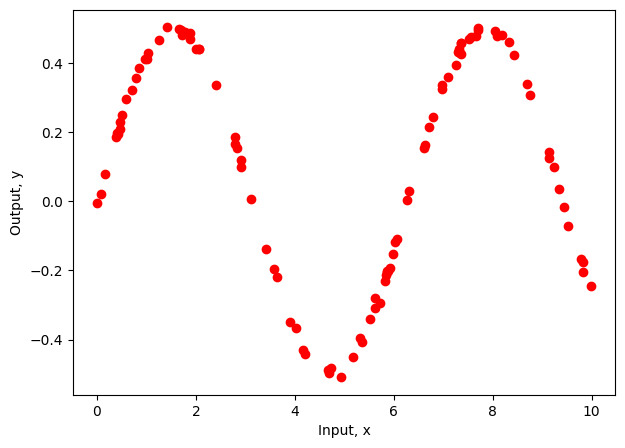

In [ ]:
# Set the seed for reproducibility
tf.random.set_seed(0)

# Generate 100 random numbers between 0 and 10
x = 10 * tf.random.uniform(shape=(100,))

# Calculate y based on the formula with some noise added
y = 0.5 * tf.math.sin(x) + 0.01 * tf.random.normal(shape=(100,))

plt.figure(figsize=(7, 5))

# Create a scatter plot of the generated points with red color
plt.scatter(x, y, color='red')
plt.xlabel('Input, x')
plt.ylabel('Output, y')
plt.show()

In [28]:
# model
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Dense(100, activation="relu", input_shape=(1, )),
        tf.keras.layers.Dense(100, activation="relu"),
        tf.keras.layers.Dense(100, activation="relu"),
        tf.keras.layers.Dense(1),
    ]
)

# compile
model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.mse)

# fit
model.fit(x, y, epochs=1000)

Epoch 1/1000
4/4 [==============================] - 1s 3ms/step - loss: 0.1897
Epoch 2/1000
4/4 [==============================] - 0s 3ms/step - loss: 0.1197
Epoch 3/1000
4/4 [==============================] - 0s 2ms/step - loss: 0.1296
Epoch 4/1000
4/4 [==============================] - 0s 3ms/step - loss: 0.1089
Epoch 5/1000
4/4 [==============================] - 0s 3ms/step - loss: 0.1109
Epoch 6/1000
4/4 [==============================] - 0s 3ms/step - loss: 0.1087
Epoch 7/1000
4/4 [==============================] - 0s 2ms/step - loss: 0.1024
Epoch 8/1000
4/4 [==============================] - 0s 2ms/step - loss: 0.1109
Epoch 9/1000
4/4 [==============================] - 0s 2ms/step - loss: 0.1031
Epoch 10/1000
4/4 [==============================] - 0s 3ms/step - loss: 0.1076
Epoch 11/1000
4/4 [==============================] - 0s 2ms/step - loss: 0.1032
Epoch 12/1000
4/4 [==============================] - 0s 5ms/step - loss: 0.1063
Epoch 13/1000
4/4 [==============================

4/4 [==============================] - 0s 1ms/step


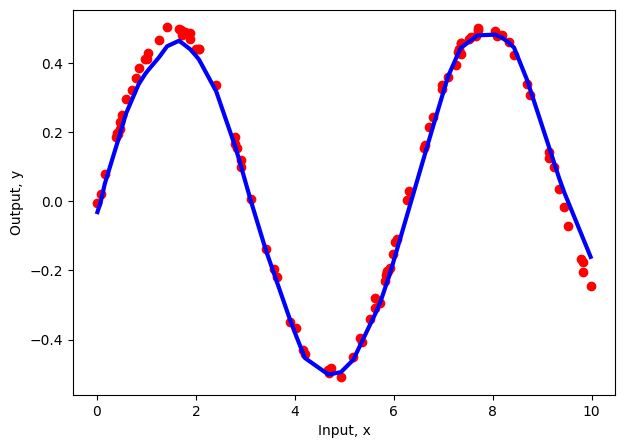

In [29]:
def plot_predictions(model, x, y):
    # Predict y values
    y_pred = model.predict(x)

    # Sort x and y_pred for line plot
    sorted_zip = sorted(zip(x, y_pred), key=lambda x: x[0])
    x_sorted, y_pred_sorted = zip(*sorted_zip)

    plt.figure(figsize=(7, 5))

    # Create a scatter plot of the actual points with red color
    plt.scatter(x, y, color='red')

    # Plot the predicted values with blue color
    plt.plot(x_sorted, y_pred_sorted, color='blue', linewidth=3)
    plt.xlabel('Input, x')
    plt.ylabel('Output, y')
    plt.show()

plot_predictions(model, x, y)

In [30]:
model.summary()

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_16 (Dense)            (None, 100)               200       
                                                                 
 dense_17 (Dense)            (None, 100)               10100     
                                                                 
 dense_18 (Dense)            (None, 100)               10100     
                                                                 
 dense_19 (Dense)            (None, 1)                 101       
                                                                 
Total params: 20,501
Trainable params: 20,501
Non-trainable params: 0
_________________________________________________________________
